In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / Path("data") / Path("regions")
OUTPUT_DIR = PROJECT_DIR / Path("phase4_2_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

CITIES = ["Delhi", "Kolkata", "Chennai", "Bengaluru", "Hyderabad"]
YEARS = list(range(2015, 2026))

VARIABLES = ["lst_c", "ndbi", "ndvi"]

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [4]:
frames = []

for city in CITIES:
    path = DATA_DIR / f"{city}_cell_year_2015_2025.csv"

    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

    df = pd.read_csv(path, low_memory=False)
    df["year"] = pd.to_numeric(df["year"], errors="coerce")

    for col in VARIABLES + ["n_obs_mean"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    frames.append(df)

data = pd.concat(frames, ignore_index=True)

print(f"Total rows: {len(data):,}")
print(f"Total columns: {len(data.columns)}")
print(f"Cities: {sorted(data['city'].dropna().unique())}")
print(f"Years: {sorted(data['year'].dropna().unique().astype(int))}")

data.head()

Total rows: 435,732
Total columns: 11
Cities: ['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata']
Years: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,grid_id,city_id,city,year,lst_c,ndvi,ndbi,n_obs_mean,l8_scenes,l9_scenes,sensor_mix
0,Delhi_24695_11665,Delhi,Delhi,2015,38.8222,0.1738,0.0780,7.0000,22,0,Landsat 8
1,Delhi_24695_11665,Delhi,Delhi,2016,42.8146,0.1432,0.0691,6.0000,24,0,Landsat 8
2,Delhi_24695_11665,Delhi,Delhi,2017,45.4215,0.1495,0.0795,5.0000,22,0,Landsat 8
3,Delhi_24695_11665,Delhi,Delhi,2018,45.6234,0.1606,0.0782,4.0000,21,0,Landsat 8
4,Delhi_24695_11665,Delhi,Delhi,2019,50.7112,0.1802,0.0680,6.0992,21,0,Landsat 8


In [5]:
structure = []

for city, group in data.groupby("city"):
    present_years = set(group["year"].dropna().astype(int))
    missing_years = sorted(set(YEARS) - present_years)

    structure.append({
        "city": city,
        "rows": len(group),
        "unique_grid_cells": group["grid_id"].nunique(),
        "year_count": len(present_years),
        "missing_years": missing_years,
        "duplicate_cell_year_rows": group.duplicated(
            ["grid_id", "year"]
        ).sum()
    })

structure_df = pd.DataFrame(structure)
structure_df

,city,rows,unique_grid_cells,year_count,missing_years,duplicate_cell_year_rows
0,Bengaluru,158840,14440,11,[],0
1,Chennai,50996,4636,11,[],0
2,Delhi,134508,12228,11,[],0
3,Hyderabad,49214,4474,11,[],0
4,Kolkata,42174,3834,11,[],0


In [8]:
missing_rows = []

for city, group in data.groupby("city"):
    for col in VARIABLES + ["n_obs_mean"]:
        if col not in group.columns:
            continue

        missing_rows.append({
            "city": city,
            "variable": col,
            "missing_count": group[col].isna().sum(),
            "missing_percent": 100 * group[col].isna().mean()
        })

missing_df = pd.DataFrame(missing_rows)
missing_df

,city,variable,missing_count,missing_percent
0,Bengaluru,lst_c,0,0.0000
1,Bengaluru,ndbi,0,0.0000
2,Bengaluru,ndvi,0,0.0000
3,Bengaluru,n_obs_mean,0,0.0000
4,Chennai,lst_c,0,0.0000
5,Chennai,ndbi,1,0.0020
6,Chennai,ndvi,1,0.0020
7,Chennai,n_obs_mean,0,0.0000
8,Delhi,lst_c,0,0.0000
9,Delhi,ndbi,0,0.0000


In [13]:
missing_by_year = (
    data.groupby(["city", "year"])[VARIABLES]
    .agg(lambda s: s.isna().mean() * 100)
    .reset_index()
)

missing_by_year.head(10)

,city,year,lst_c,ndbi,ndvi
0,Bengaluru,2015,0.0000,0.0000,0.0000
1,Bengaluru,2016,0.0000,0.0000,0.0000
2,Bengaluru,2017,0.0000,0.0000,0.0000
3,Bengaluru,2018,0.0000,0.0000,0.0000
4,Bengaluru,2019,0.0000,0.0000,0.0000
5,Bengaluru,2020,0.0000,0.0000,0.0000
6,Bengaluru,2021,0.0000,0.0000,0.0000
7,Bengaluru,2022,0.0000,0.0000,0.0000
8,Bengaluru,2023,0.0000,0.0000,0.0000
9,Bengaluru,2024,0.0000,0.0000,0.0000


In [14]:
overall_stats = data[VARIABLES].describe().T
overall_stats

,count,mean,std,min,25%,50%,75%,max
lst_c,435732.0000,40.1893,4.3494,25.6850,37.8413,40.5069,43.0397,56.8557
ndbi,435731.0000,0.0080,0.1016,-1.3134,-0.0367,0.0134,0.0603,0.9913
ndvi,435731.0000,0.3128,0.1310,-0.5003,0.2373,0.3103,0.3909,0.8752


In [15]:
city_stats = (
    data.groupby("city")[VARIABLES]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

city_stats

lst_c                                           ndbi          \
            count    mean  median    std     min     max   count    mean   
city                                                                       
Bengaluru  158840 39.8618 39.8125 3.6116 26.2926 53.0527  158840  0.0285   
Chennai     50996 37.1736 39.7249 6.5658 26.8323 52.3387   50995  0.0558   
Delhi      134508 41.6327 41.3028 3.7271 26.1002 56.8557  134508  0.0032   
Hyderabad   49214 42.4083 42.3816 2.8222 28.2411 55.9513   49214  0.0088   
Kolkata     42174 37.8760 38.0942 3.3850 25.6850 48.7002   42174 -0.1129   

                                           ndvi                               \
           median    std     min    max   count   mean median    std     min   
city                                                                           
Bengaluru  0.0422 0.0836 -0.5539 0.2836  158840 0.3901 0.3800 0.0986 -0.3487   
Chennai    0.0071 0.1676 -1.3134 0.9913   50995 0.2053 0.2564 0.1827 -0.5003   
Delhi      0.0096 0.0602 -0.5019 0.2203  134508 0.2591 0.2468 0.0780 -0.1378   
Hyderabad  0.0146 0.0647 -0.5279 0.1969   49214 0.2868 0.2693 0.0894 -0.2425   
Kolkata   -0.0887 0.1040 -0.6723 0.1082   42174 0.3529 0.3542 0.1532 -0.4925   

                  
             max  
city              
Bengaluru 0.8752  
Chennai   0.8092  
Delhi     0.8183  
Hyderabad 0.7928  
Kolkata   0.7921

In [16]:
city_year_stats = (
    data.groupby(["city", "year"])[VARIABLES]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

city_year_stats.head(20)

lst_c                                          ndbi          \
                count    mean  median    std     min     max  count    mean   
city      year                                                                
Bengaluru 2015  14440 37.9785 38.0296 2.2506 27.9795 49.5940  14440  0.0017   
          2016  14440 42.1965 42.4627 3.2903 29.7929 52.7810  14440  0.0418   
          2017  14440 41.6005 41.6118 2.8679 30.8445 51.0175  14440  0.0583   
          2018  14440 36.2262 36.0268 2.7784 26.2926 49.1009  14440 -0.0004   
          2019  14440 40.6770 40.7796 3.3578 29.1995 51.6543  14440  0.0458   
          2020  14440 41.3385 41.7074 3.0659 28.0797 50.4174  14440  0.0500   
          2021  14440 39.8476 40.0299 3.1245 28.0214 49.9572  14440  0.0477   
          2022  14440 37.5736 37.8462 2.7373 26.7741 46.6601  14440  0.0081   
          2023  14440 38.7313 38.8548 3.0382 27.1795 49.9455  14440 -0.0095   
          2024  14440 43.5560 43.8148 2.8449 28.9160 53.0527  14440  0.0634   
          2025  14440 38.7544 38.9562 2.6316 28.6794 49.1993  14440  0.0069   
Chennai   2015   4636 37.2541 39.5413 5.7562 27.5668 50.6586   4636  0.0527   
          2016   4636 37.5766 40.5851 6.2148 28.9744 49.7655   4636  0.0522   
          2017   4636 36.9267 40.0500 6.3852 27.0207 48.8961   4636  0.0824   
          2018   4636 35.5776 38.0747 6.0740 26.8481 50.0392   4635  0.0456   
          2019   4636 38.8715 43.4043 7.9250 27.9975 52.0656   4636  0.0487   
          2020   4636 37.9883 41.3389 6.7795 28.7140 51.1450   4636  0.0427   
          2021   4636 36.2328 38.2937 5.4196 27.5274 50.0229   4636  0.0431   
          2022   4636 38.7250 42.6581 7.5581 26.8323 52.3387   4636  0.0258   
          2023   4636 36.7908 39.8273 6.5282 27.7243 49.7344   4636  0.0659   

                                               ndvi                       \
                median    std     min    max  count   mean median    std   
city      year                                                             
Bengaluru 2015  0.0120 0.0813 -0.4977 0.1936  14440 0.4252 0.4175 0.0935   
          2016  0.0549 0.0779 -0.5387 0.2548  14440 0.3698 0.3612 0.0872   
          2017  0.0719 0.0805 -0.4958 0.2768  14440 0.3610 0.3508 0.0884   
          2018  0.0138 0.0851 -0.4882 0.2344  14440 0.4225 0.4126 0.1016   
          2019  0.0586 0.0776 -0.4783 0.2605  14440 0.3513 0.3418 0.0887   
          2020  0.0617 0.0732 -0.4740 0.2836  14440 0.3714 0.3629 0.0870   
          2021  0.0584 0.0723 -0.4550 0.2044  14440 0.3818 0.3747 0.0836   
          2022  0.0208 0.0801 -0.4739 0.1909  14440 0.4235 0.4175 0.0902   
          2023  0.0045 0.0893 -0.5539 0.1876  14440 0.4328 0.4244 0.1092   
          2024  0.0752 0.0732 -0.4982 0.2374  14440 0.3235 0.3176 0.0772   
          2025  0.0182 0.0833 -0.4962 0.2667  14440 0.4285 0.4203 0.0983   
Chennai   2015  0.0061 0.1555 -0.6505 0.4487   4636 0.2273 0.2806 0.1830   
          2016 -0.0108 0.1821 -0.5533 0.7426   4636 0.1715 0.2692 0.2276   
          2017  0.0317 0.1448 -0.5737 0.5792   4636 0.1791 0.2259 0.1482   
          2018  0.0063 0.1479 -0.6280 0.7349   4635 0.2080 0.2531 0.1590   
          2019  0.0265 0.1213 -0.5832 0.3096   4636 0.1740 0.2363 0.1750   
          2020  0.0074 0.1663 -1.3134 0.9913   4636 0.1958 0.2693 0.2040   
          2021  0.0022 0.1596 -0.5366 0.4685   4636 0.2361 0.2760 0.1667   
          2022 -0.0042 0.1305 -0.4442 0.4221   4636 0.2114 0.2625 0.1679   
          2023 -0.0058 0.2060 -0.4319 0.7566   4636 0.2254 0.2711 0.1787   

                               
                   min    max  
city      year                 
Bengaluru 2015 -0.2408 0.8366  
          2016 -0.2406 0.8675  
          2017 -0.0851 0.8703  
          2018 -0.2183 0.8517  
          2019 -0.1449 0.8485  
          2020 -0.3487 0.8303  
          2021 -0.1453 0.8302  
          2022 -0.1701 0.8555  
          2023 -0.1957 0.8752  
          2024 -0.1730 0.8717  
          2025 -0.0461 0.8685  
C

In [17]:
plausibility_checks = {
    "lst_c": (0, 80),
    "ndbi": (-1, 1),
    "ndvi": (-1, 1)
}

for variable, (lower, upper) in plausibility_checks.items():
    outside = data[
        data[variable].notna()
        & ~data[variable].between(lower, upper)
    ]

    print(
        f"{variable}: {len(outside):,} values outside "
        f"[{lower}, {upper}]"
    )

lst_c: 0 values outside [0, 80]
ndbi: 1 values outside [-1, 1]
ndvi: 0 values outside [-1, 1]


In [ ]:
required = ["lst_c", "ndvi", "ndbi"]

null_mask = data[required].isna().any(axis=1)

out_of_range_mask = (
    ~data["lst_c"].between(0, 80)
    | ~data["ndvi"].between(-1, 1)
    | ~data["ndbi"].between(-1, 1)
)

print("Total rows:", len(data))
print("Rows with null required variables:", null_mask.sum())
print("Rows with out-of-range values:", out_of_range_mask.sum())
print(
    "Rows removed (union of both conditions):",
    (null_mask | out_of_range_mask).sum()
)

Total rows: 435732
Rows with null required variables: 1
Rows with out-of-range values: 2
Rows removed (union of both conditions): 2


In [20]:
invalid_mask = null_mask | out_of_range_mask

clean_data = data.loc[~invalid_mask].copy()

print("Original rows:", len(data))
print("Cleaned rows:", len(clean_data))
print("Removed rows:", len(data) - len(clean_data))
print(
    "Remaining invalid values:",
    (
        clean_data[required].isna().any(axis=1)
        | ~clean_data["lst_c"].between(0, 80)
        | ~clean_data["ndvi"].between(-1, 1)
        | ~clean_data["ndbi"].between(-1, 1)
    ).sum()
)

Original rows: 435732
Cleaned rows: 435730
Removed rows: 2
Remaining invalid values: 0


In [21]:
data = clean_data

In [22]:
data.head(15)

,grid_id,city_id,city,year,lst_c,ndvi,ndbi,n_obs_mean,l8_scenes,l9_scenes,sensor_mix
0,Delhi_24695_11665,Delhi,Delhi,2015,38.8222,0.1738,0.0780,7.0000,22,0,Landsat 8
1,Delhi_24695_11665,Delhi,Delhi,2016,42.8146,0.1432,0.0691,6.0000,24,0,Landsat 8
2,Delhi_24695_11665,Delhi,Delhi,2017,45.4215,0.1495,0.0795,5.0000,22,0,Landsat 8
3,Delhi_24695_11665,Delhi,Delhi,2018,45.6234,0.1606,0.0782,4.0000,21,0,Landsat 8
4,Delhi_24695_11665,Delhi,Delhi,2019,50.7112,0.1802,0.0680,6.0992,21,0,Landsat 8
5,Delhi_24695_11665,Delhi,Delhi,2020,40.2345,0.1907,0.0430,4.5749,22,0,Landsat 8
6,Delhi_24695_11665,Delhi,Delhi,2021,44.5033,0.1787,0.0611,6.7642,19,0,Landsat 8
7,Delhi_24695_11665,Delhi,Delhi,2022,44.7177,0.1942,0.0561,13.0000,22,21,Landsat 8 + Landsat 9
8,Delhi_24695_11665,Delhi,Delhi,2023,42.2139,0.2172,0.0627,6.0087,21,21,Landsat 8 + Landsat 9
9,Delhi_24695_11665,Delhi,Delhi,2024,44.8901,0.1970,0.0599,13.0000,22,22,Landsat 8 + Landsat 9


In [27]:
data.to_csv(DATA_DIR / "data.csv", index=False)

In [23]:
outlier_rows = []

for city, group in data.groupby("city"):
    for variable in VARIABLES:
        values = group[variable].dropna()

        if values.empty:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        count = (
            (values < lower) | (values > upper)
        ).sum()

        outlier_rows.append({
            "city": city,
            "variable": variable,
            "lower_bound": lower,
            "upper_bound": upper,
            "outlier_count": int(count),
            "outlier_percent": 100 * count / len(values)
        })

outlier_df = pd.DataFrame(outlier_rows)
outlier_df

,city,variable,lower_bound,upper_bound,outlier_count,outlier_percent
0,Bengaluru,lst_c,29.8281,49.9997,457,0.2877
1,Bengaluru,ndbi,-0.1533,0.2285,5670,3.5696
2,Bengaluru,ndvi,0.1462,0.6242,4496,2.8305
3,Chennai,lst_c,9.8885,62.3255,0,0.0000
4,Chennai,ndbi,-0.3275,0.4408,1560,3.0592
5,Chennai,ndvi,-0.3828,0.7574,24,0.0471
6,Delhi,lst_c,31.5618,51.4898,1415,1.0520
7,Delhi,ndbi,-0.1375,0.1522,2780,2.0668
8,Delhi,ndvi,0.0605,0.4443,3521,2.6177
9,Hyderabad,lst_c,35.5330,49.3410,1031,2.0949


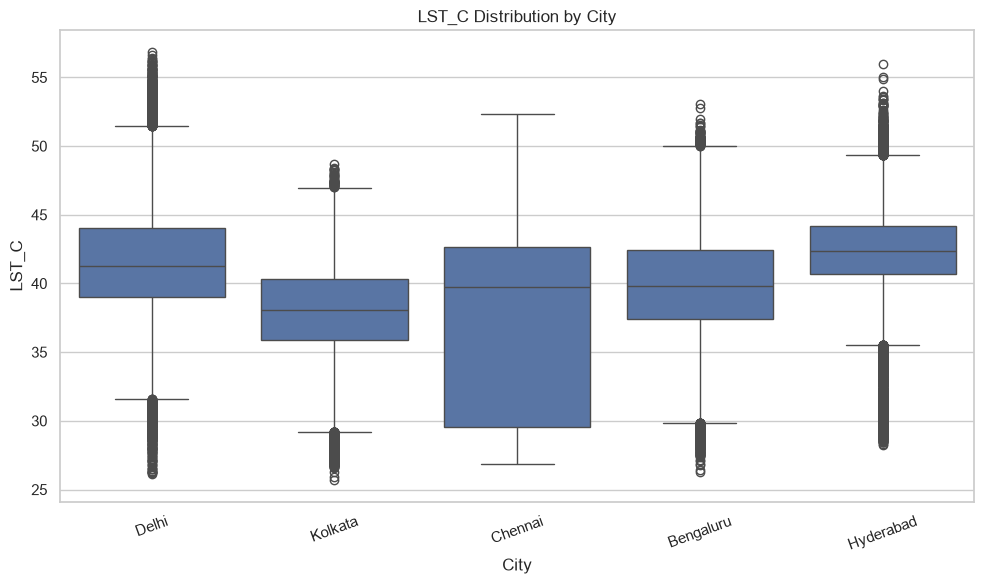

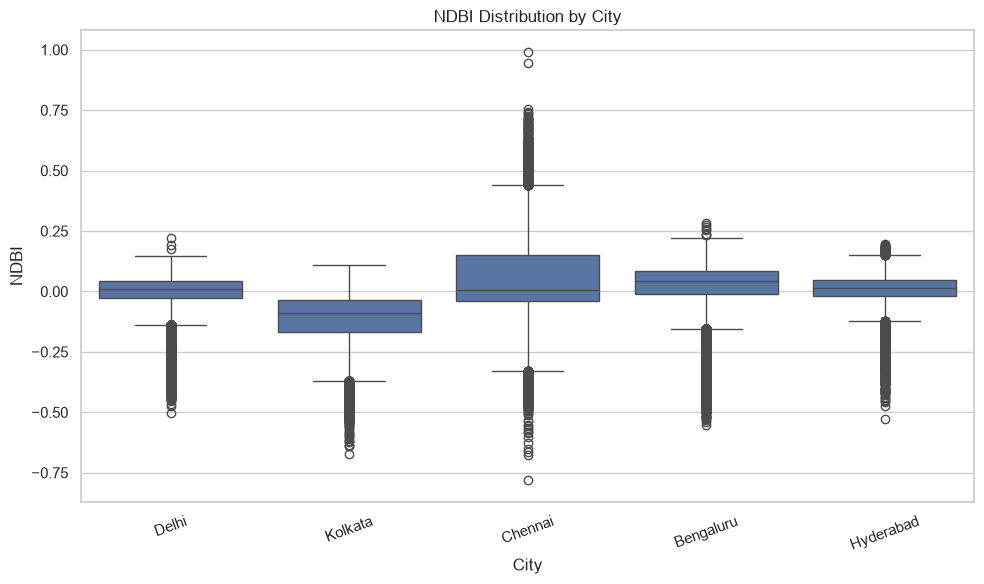

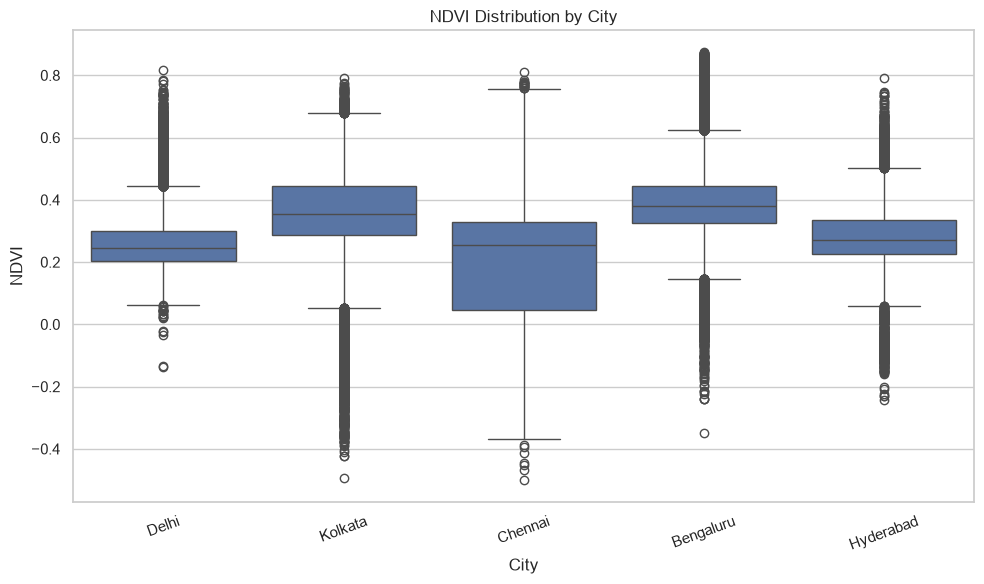

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

for variable in VARIABLES:
    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=data,
        x="city",
        y=variable,
        order=CITIES,
        showfliers=True
    )

    plt.title(f"{variable.upper()} Distribution by City")
    plt.xlabel("City")
    plt.ylabel(variable.upper())
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

In [25]:
data[data['lst_c']>=50]

,grid_id,city_id,city,year,lst_c,ndvi,ndbi,n_obs_mean,l8_scenes,l9_scenes,sensor_mix
4,Delhi_24695_11665,Delhi,Delhi,2019,50.7112,0.1802,0.0680,6.0992,21,0,Landsat 8
15,Delhi_24695_11666,Delhi,Delhi,2019,51.4586,0.1912,0.0768,6.0000,21,0,Landsat 8
26,Delhi_24695_11667,Delhi,Delhi,2019,51.0627,0.1778,0.0800,6.0000,21,0,Landsat 8
37,Delhi_24695_11668,Delhi,Delhi,2019,52.5126,0.1397,0.0847,6.0427,21,0,Landsat 8
48,Delhi_24695_11669,Delhi,Delhi,2019,51.9395,0.1317,0.1152,6.9928,21,0,Landsat 8
...,...,...,...,...,...,...,...,...,...,...,...
433005,Hyderabad_25268_7286,Hyderabad,Hyderabad,2016,50.8107,0.2256,0.0630,5.0000,8,0,Landsat 8
433015,Hyderabad_25268_7287,Hyderabad,Hyderabad,2015,51.3670,0.2261,0.0437,5.0000,6,0,Landsat 8
433016,Hyderabad_25268_7287,Hyderabad,Hyderabad,2016,50.5019,0.2428,0.0478,5.0000,8,0,Landsat 8
433686,Hyderabad_25269_7285,Hyderabad,Hyderabad,2015,52.9965,0.1950,0.0735,5.0000,6,0,Landsat 8
